# Satellite Orbit Explorer · built during Space Career Week 2026 · GNSS Academy

### 8 Stages of Development:
1. **Setup**: Imports, constants, directories, and configuration. (We are here)
2. **Load GP JSON**: Fetch or load General Perturbation satellite metadata.
3. **Parse Elements**: Extract Keplerian orbital elements from the GP records.
4. **Time Window**: Set up the propagation timeline.
5. **Propagate**: Compute the orbital state vectors over time using a two-body Kepler model.
6. **Orbit Summary**: Calculate statistics like perigee, apogee, and orbital period.
7. **Plots**: Visualize the 2D ground track and 3D orbit trajectory.
8. **KML and Report**: Export results to Google Earth KML format and summarize.

In [4]:
import json
import math
import time
import zipfile
import xml.etree.ElementTree as ET
from datetime import datetime, timedelta, timezone
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
import requests

# --- Physical Constants ---
# Standard gravitational parameter for Earth (km^3 / s^2)
MU_EARTH_KM3_S2 = 398600.4418
# Earth's equatorial radius (km)
EARTH_RADIUS_KM = 6378.137

# --- Directory Setup ---
BASE_DIR = Path('/content/satellite_orbits')
IN_DIR = BASE_DIR / 'inputs'
OUT_DIR = BASE_DIR / 'outputs'

IN_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Propagation Configuration ---
STEP_SECONDS = 5
DURATION_HOURS = 24
LIVE_GROUP = None

# Print configuration to report success
print("--- Stage 1: Setup Completed Successfully ---")
print(f"Input Directory:  {IN_DIR}")
print(f"Output Directory: {OUT_DIR}")
print(f"Propagation Step: {STEP_SECONDS} seconds")
print(f"Duration:         {DURATION_HOURS} hours")
print(f"Live Group:       {LIVE_GROUP}")
print(f"Earth MU:         {MU_EARTH_KM3_S2} km^3/s^2")
print(f"Earth Radius:     {EARTH_RADIUS_KM} km")


--- Stage 1: Setup Completed Successfully ---
Input Directory:  /content/satellite_orbits/inputs
Output Directory: /content/satellite_orbits/outputs
Propagation Step: 5 seconds
Duration:         24 hours
Live Group:       None
Earth MU:         398600.4418 km^3/s^2
Earth Radius:     6378.137 km


### Stage 2: Load GP JSON

OMM JSON (Orbit Mean-Elements Message in JSON format) is significantly easier to work with than the traditional two-line element (TLE) format because it stores parameters in explicitly named fields with standardized units, avoiding complex character-position-based parsing. Furthermore, OMM JSON represents timestamps in ISO 8601 UTC date-time format and seamlessly handles modern, six-digit NORAD catalog numbers without structural overflow issues.

In [7]:
def extract_inputs():
    """Verify and extract required workshop inputs from an uploaded ZIP archive if not present."""
    required_files = ['orbital_elements.json', 'data_manifest.json', 'world_map.txt']
    all_exist = all((IN_DIR / f).exists() for f in required_files)

    if all_exist:
        print("All required input files already exist in IN_DIR.")
        return

    # Instruct user to drag and drop the zip file
    print("--- Action Required ---")
    print("Please upload 'orbit_workshop_inputs.zip' by dragging it into the Colab Files panel (/content).")
    print("Waiting for upload...")

    timeout = time.time() + 900  # 15 minutes timeout
    zip_path = None

    while time.time() < timeout:
        # Look for files matching 'orbit_workshop_inputs*.zip'
        matches = list(Path('/content').glob('orbit_workshop_inputs*.zip'))
        if matches:
            potential_zip = matches[0]
            if zipfile.is_zipfile(potential_zip):
                zip_path = potential_zip
                break
        time.sleep(2)

    if not zip_path:
        raise TimeoutError("Timed out waiting for 'orbit_workshop_inputs.zip' to be uploaded.")

    print(f"Found valid ZIP archive: {zip_path}. Extracting files...")
    with zipfile.ZipFile(zip_path, 'r') as ref:
        # Only extract the three required files to IN_DIR
        for member in ref.namelist():
            name = Path(member).name
            if name in required_files:
                target_path = IN_DIR / name
                with ref.open(member) as source, open(target_path, 'wb') as target:
                    target.write(source.read())
                print(f"Extracted: {name} -> {target_path}")


def read_gp_json(path):
    """Load and validate General Perturbation satellite metadata in OMM JSON format."""
    if not path.exists():
        raise FileNotFoundError(f"Expected file not found: {path}")

    with open(path, 'r') as f:
        data = json.load(f)

    required_keys = {
        'OBJECT_NAME', 'NORAD_CAT_ID', 'EPOCH', 'MEAN_MOTION',
        'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE',
        'ARG_OF_PERICENTER', 'MEAN_ANOMALY'
    }

    # Validate presence of standard OMM fields in every record
    for idx, record in enumerate(data):
        missing = required_keys - record.keys()
        if missing:
            raise ValueError(f"Record at index {idx} ({record.get('OBJECT_NAME', 'Unknown')}) is missing keys: {missing}")

    return data

# --- Execution of Stage 2 ---
extract_inputs()

sats = read_gp_json(IN_DIR / 'orbital_elements.json')

# Load and display manifest info
with open(IN_DIR / 'data_manifest.json', 'r') as f:
    data_manifest = json.load(f)

source_note = f"Source: {data_manifest.get('source', 'CelesTrak')} - Retrieved UTC: {data_manifest.get('retrieved_utc', 'N/A')}"
print(f"\n{source_note}")
print(f"Loaded {len(sats)} satellites:")
for s in sats:
    print(f"- {s['OBJECT_NAME']} (NORAD ID: {s['NORAD_CAT_ID']}, Epoch: {s['EPOCH']})")


--- Action Required ---
Please upload 'orbit_workshop_inputs.zip' by dragging it into the Colab Files panel (/content).
Waiting for upload...
Found valid ZIP archive: /content/orbit_workshop_inputs.zip. Extracting files...
Extracted: orbital_elements.json -> /content/satellite_orbits/inputs/orbital_elements.json
Extracted: data_manifest.json -> /content/satellite_orbits/inputs/data_manifest.json
Extracted: world_map.txt -> /content/satellite_orbits/inputs/world_map.txt

Source: CelesTrak - Retrieved UTC: 2026-11-10T16:30:32Z
Loaded 4 satellites:
- PULSAR-0 (NORAD ID: 64541, Epoch: 2026-11-10T04:10:34.900320)
- GSAT0225 (GALILEO 29) (NORAD ID: 59598, Epoch: 2026-11-09T08:30:06.579648)
- SES-5 (NORAD ID: 38652, Epoch: 2026-11-10T04:02:09.139776)
- QZS-2 (MICHIBIKI-2) (NORAD ID: 42738, Epoch: 2026-10-17T15:21:52.982784)


In [8]:
# --- Optional Live CelesTrak Extension ---
import os

if LIVE_GROUP is None:
    print("LIVE_GROUP is None. Using the default workshop snapshot data.")
else:
    cache_path = IN_DIR / f'gp_{LIVE_GROUP}.json'
    cache_valid = False

    # Check if a cached copy exists and is less than 2 hours old
    if cache_path.exists():
        file_age_hours = (time.time() - cache_path.stat().st_mtime) / 3600.0
        if file_age_hours < 2.0:
            cache_valid = True
            print(f"Using cached live data from {cache_path} (Age: {file_age_hours:.2f} hours)")

    if not cache_valid:
        url = f"https://celestrak.org/NORAD/elements/gp.php?GROUP={LIVE_GROUP}&FORMAT=JSON"
        print(f"Fetching live elements for group '{LIVE_GROUP}' from CelesTrak...")
        try:
            resp = requests.get(url, timeout=30)
            resp.raise_for_status()
            live_data = resp.json()

            # Quick validation of standard schema structure
            if not isinstance(live_data, list) or len(live_data) == 0:
                raise ValueError("Invalid or empty JSON response received from CelesTrak.")

            # Save valid response to cache
            with open(cache_path, 'w') as f:
                json.dump(live_data, f)
            print(f"Cached updated elements successfully to {cache_path}")
        except Exception as e:
            print(f"Failed to download live data from CelesTrak: {e}")
            print("Falling back to local cache file if available...")
            if cache_path.exists():
                with open(cache_path, 'r') as f:
                    live_data = json.load(f)
            else:
                raise

    # Reload elements from the validated local cache file
    with open(cache_path, 'r') as f:
        raw_live_sats = json.load(f)

    # Sort by NORAD Catalog ID to keep order deterministic, then keep first four
    sorted_live = sorted(raw_live_sats, key=lambda x: int(x['NORAD_CAT_ID']))
    sats = sorted_live[:4]

    # Update runtime source tracking info
    retrieval_time = datetime.fromtimestamp(cache_path.stat().st_mtime, tz=timezone.utc).isoformat()
    source_note = f"Source: Live CelesTrak (Group: {LIVE_GROUP}) - Cached UTC: {retrieval_time}"

    print(f"\n{source_note}")
    print(f"Selected {len(sats)} satellites from live group '{LIVE_GROUP}':")
    for s in sats:
        print(f"- {s['OBJECT_NAME']} (NORAD ID: {s['NORAD_CAT_ID']}, Epoch: {s['EPOCH']})")

LIVE_GROUP is None. Using the default workshop snapshot data.


In [9]:
# --- Verify Satellite Selection ---
print("=== Satellite Selection Verification ===")
print(f"Active Source: {source_note}")
print(f"Total Satellites Loaded: {len(sats)}")
for idx, s in enumerate(sats):
    print(f"{idx + 1}. Name: {s['OBJECT_NAME']:<25} | NORAD ID: {s['NORAD_CAT_ID']:<6} | Epoch: {s['EPOCH']}")

=== Satellite Selection Verification ===
Active Source: Source: CelesTrak - Retrieved UTC: 2026-11-10T16:30:32Z
Total Satellites Loaded: 4
1. Name: PULSAR-0                  | NORAD ID: 64541  | Epoch: 2026-11-10T04:10:34.900320
2. Name: GSAT0225 (GALILEO 29)     | NORAD ID: 59598  | Epoch: 2026-11-09T08:30:06.579648
3. Name: SES-5                     | NORAD ID: 38652  | Epoch: 2026-11-10T04:02:09.139776
4. Name: QZS-2 (MICHIBIKI-2)       | NORAD ID: 42738  | Epoch: 2026-10-17T15:21:52.982784


### Stage 3: Parse Elements

To perform numerical orbit propagation, we convert the General Perturbation (GP) parameters into standard Keplerian elements. The following table maps the standard GP field names to their astronomical symbols and physical conversion formulas:

| GP JSON Field | Symbol | Description | Mathematical Conversion / Unit |
| :--- | :---: | :--- | :--- |
| `MEAN_MOTION` | $n$ | Mean Motion | $\text{rad/s} = 2\pi \times \text{MEAN}\_\text{MOTION} / 86400$ |
| — | $a$ | Semi-major Axis | $a = \left(\frac{\mu_{Earth}}{n^2}\right)^{1/3}$ [km] |
| `ECCENTRICITY` | $e$ | Eccentricity | Dimensionless (decimal format) |
| `INCLINATION` | $i$ | Inclination | Radians (converted from degrees) |
| `RA_OF_ASC_NODE`| $\Omega$| Right Ascension of Ascending Node | Radians (converted from degrees) |
| `ARG_OF_PERICENTER`| $\omega$| Argument of Perigee | Radians (converted from degrees) |
| `MEAN_ANOMALY` | $M_0$ | Mean Anomaly at Epoch | Radians (converted from degrees) |

> **Educational Note:** The parameters provided in the CelesTrak GP records are SGP4 *mean* elements designed specifically for the SGP4 analytical propagation model (which accounts for non-spherical Earth perturbations, atmospheric drag, etc.). Treating these as classical two-body osculating Keplerian elements is an educational simplification; it will not perfectly match precision ephemeris but provides an excellent approximation for learning orbital mechanics.

In [10]:
def parse_gp_epoch(text):
    """Parse ISO 8601 UTC timestamp format from CelesTrak."""
    # Normalize the suffix to ensure UTC timezone awareness
    cleaned = text.rstrip('Z')
    return datetime.fromisoformat(cleaned).replace(tzinfo=timezone.utc)


def parse_gp_elements(rec):
    """Convert OMM GP record into Keplerian elements in model units (km, rad, s)."""
    name = rec['OBJECT_NAME']
    norad_id = int(rec['NORAD_CAT_ID'])
    epoch = parse_gp_epoch(rec['EPOCH'])

    # Convert mean motion from rev/day to rad/s
    mean_motion_rev_day = rec['MEAN_MOTION']
    n_rad_s = (2 * math.pi * mean_motion_rev_day) / 86400.0

    # Calculate semi-major axis (a) using Kepler's Third Law: a = (mu / n^2)^(1/3)
    a_km = (MU_EARTH_KM3_S2 / (n_rad_s ** 2)) ** (1.0 / 3.0)

    # Convert orbital angles from degrees to radians
    i_rad = math.radians(rec['INCLINATION'])
    raan_rad = math.radians(rec['RA_OF_ASC_NODE'])
    argp_rad = math.radians(rec['ARG_OF_PERICENTER'])
    M0_rad = math.radians(rec['MEAN_ANOMALY'])

    return {
        'name': name,
        'norad_id': norad_id,
        'label': f"{name} [{norad_id}]",
        'epoch': epoch,
        'n_rad_s': n_rad_s,
        'a_km': a_km,
        'e': rec['ECCENTRICITY'],
        'i_rad': i_rad,
        'raan_rad': raan_rad,
        'argp_rad': argp_rad,
        'M0_rad': M0_rad
    }


def elements_table(elements):
    """Return a list of formatted text rows representing the parsed elements."""
    headers = ["Satellite Name", "NORAD ID", "Epoch (UTC)", "a (km)", "e", "i (deg)", "RAAN (deg)", "ArgP (deg)", "M0 (deg)"]
    # Use a simpler format string for text headers
    header_format = "{:<24} | {:<8} | {:<23} | {:<9} | {:<8} | {:<7} | {:<10} | {:<10} | {:<8}"
    # Numeric formatting for data rows
    row_format = "{:<24} | {:<8} | {:<23} | {:<9.2f} | {:<8.6f} | {:<7.2f} | {:<10.2f} | {:<10.2f} | {:<8.2f}"

    lines = []
    header_line = header_format.format(*headers)
    lines.append(header_line)
    lines.append("-" * len(header_line))

    for el in elements:
        lines.append(row_format.format(
            el['name'][:24],
            el['norad_id'],
            el['epoch'].strftime('%Y-%m-%d %H:%M:%S'),
            el['a_km'],
            el['e'],
            math.degrees(el['i_rad']),
            math.degrees(el['raan_rad']),
            math.degrees(el['argp_rad']),
            math.degrees(el['M0_rad'])
        ))
    return lines


# --- Run Stage 3 ---
# Verify 'sats' exists from Stage 2
if 'sats' not in globals():
    raise NameError("Missing earlier stage dependencies: 'sats' is not defined.")

elements = [parse_gp_elements(s) for s in sats]

table_output = elements_table(elements)
for line in table_output:
    print(line)

Satellite Name           | NORAD ID | Epoch (UTC)             | a (km)    | e        | i (deg) | RAAN (deg) | ArgP (deg) | M0 (deg)
-----------------------------------------------------------------------------------------------------------------------------------
PULSAR-0                 | 64541    | 2026-11-10 04:10:34     | 6880.97   | 0.000408 | 97.48   | 67.63      | 54.16      | 306.00  
GSAT0225 (GALILEO 29)    | 59598    | 2026-11-09 08:30:06     | 29600.26  | 0.000159 | 55.22   | 97.02      | 171.21     | 226.89  
SES-5                    | 38652    | 2026-11-10 04:02:09     | 42164.28  | 0.000191 | 0.05    | 32.20      | 188.01     | 254.68  
QZS-2 (MICHIBIKI-2)      | 42738    | 2026-10-17 15:21:52     | 42170.36  | 0.074521 | 39.25   | 241.35     | 270.89     | 243.82  


### Stage 4: Time Window

To compare or visualize the positions of multiple satellites simultaneously, they must be evaluated on a common UTC time grid. Because our simple Keplerian model propagates orbits starting from each satellite's individual epoch, the prediction error increases over time due to unmodeled perturbations (such as J2 perturbations, atmospheric drag, and solar pressure). Computing the time offset between a satellite's unique epoch and our simulation start is crucial: for instance, the `QZS-2` record dates back to October 17, 2026, meaning its computed position will have accumulated significantly more model divergence compared to the more recent records.

In [11]:
# --- Run Stage 4: Set up Time Window ---
if 'elements' not in globals():
    raise NameError("Missing earlier stage dependencies: 'elements' is not defined.")

# 1. Identify the newest epoch among all loaded satellites
newest_epoch = max(el['epoch'] for el in elements)

# 2. Floor the newest epoch to UTC midnight
sim_start = newest_epoch.replace(hour=0, minute=0, second=0, microsecond=0)
sim_end = sim_start + timedelta(hours=DURATION_HOURS)

# 3. Create the common UTC time grid
total_seconds = int((sim_end - sim_start).total_seconds())
n_points = (total_seconds // STEP_SECONDS) + 1
times = [sim_start + timedelta(seconds=i * STEP_SECONDS) for i in range(n_points)]

print("--- Simulation Time Window ---")
print(f"Start (UTC): {sim_start}")
print(f"End (UTC):   {sim_end}")
print(f"Step Size:   {STEP_SECONDS} s")
print(f"Grid Points: {n_points}\n")

print("--- Epoch Offset Checks ---")
for el in elements:
    offset_days = (sim_start - el['epoch']).total_seconds() / 86400.0
    stale_flag = "[STALE RECORD]" if offset_days > 7.0 or offset_days < -7.0 else "[OK]"
    print(f"- {el['label']}:")
    print(f"  Epoch:  {el['epoch']}")
    print(f"  Offset: {offset_days:.2f} days {stale_flag}")


--- Simulation Time Window ---
Start (UTC): 2026-11-10 00:00:00+00:00
End (UTC):   2026-11-11 00:00:00+00:00
Step Size:   5 s
Grid Points: 17281

--- Epoch Offset Checks ---
- PULSAR-0 [64541]:
  Epoch:  2026-11-10 04:10:34.900320+00:00
  Offset: -0.17 days [OK]
- GSAT0225 (GALILEO 29) [59598]:
  Epoch:  2026-11-09 08:30:06.579648+00:00
  Offset: 0.65 days [OK]
- SES-5 [38652]:
  Epoch:  2026-11-10 04:02:09.139776+00:00
  Offset: -0.17 days [OK]
- QZS-2 (MICHIBIKI-2) [42738]:
  Epoch:  2026-10-17 15:21:52.982784+00:00
  Offset: 23.36 days [STALE RECORD]


### Stage 5: Propagate

In this stage, we simulate the satellite's movement through space and its apparent position over a spherical, rotating Earth. The model relies on:
1. **Kepler's Equation Solver**: Translates the linearly-evolving Mean Anomaly ($M$) to Eccentric Anomaly ($E$) using numerical root-finding (Newton-Raphson).
2. **Orbit Coordinates**: Computes the radial distance ($r$) and true anomaly ($\nu$) to map positions onto the 3D orbital plane, rotating them into Geocentric Inertial (ECI) coordinates using the orientation angles (Inclinaton $i$, RAAN $\Omega$, and Argument of Perigee $\omega$).
3. **Greenwich Rotation**: Converts inertial coordinates into the Earth-centered Earth-fixed (ECEF) rotating frame using Greenwich Mean Sidereal Time (GMST).
4. **Geodetic Mapping & Vis-Viva Speed**: Computes geocentric latitude, longitude, altitude, and instantaneous orbital speed using the classical Vis-Viva energy equation.

In [12]:
def solve_kepler(M, e):
    """Solve Kepler's Equation M = E - e*sin(E) using Newton-Raphson method."""
    # Initial guess
    E = math.pi if e > 0.8 else M
    tol = 1e-12
    max_iter = 50

    for _ in range(max_iter):
        f = E - e * math.sin(E) - M
        f_prime = 1.0 - e * math.cos(E)
        delta = f / f_prime
        E -= delta
        if abs(delta) < tol:
            return E
    raise RuntimeError(f"Kepler equation did not converge. M={M}, e={e}")


def gmst_rad(t):
    """Calculate Greenwich Mean Sidereal Time (GMST) in radians for a given UTC datetime."""
    # J2000 epoch is 2000-01-01 12:00:00 UTC
    j2000 = datetime(2000, 1, 1, 12, 0, 0, tzinfo=timezone.utc)
    d = (t - j2000).total_seconds() / 86400.0
    T = d / 36525.0

    # IAU-1982 Formula (Meeus Eq. 12.4)
    theta_deg = 280.46061837 + 360.98564736629 * d + 0.000387933 * (T ** 2) - (T ** 3) / 38710000.0
    return math.radians(theta_deg % 360.0)


def propagate(el, times):
    """Propagate the Keplerian elements over a list of UTC times."""
    orbit_track = []
    a = el['a_km']
    e = el['e']
    i = el['i_rad']
    raan = el['raan_rad']
    argp = el['argp_rad']
    M0 = el['M0_rad']
    n = el['n_rad_s']
    epoch = el['epoch']

    for t in times:
        # 1) Time delta from epoch and Mean Anomaly prediction
        dt_sec = (t - epoch).total_seconds()
        M = (M0 + n * dt_sec) % (2.0 * math.pi)

        # 2) Solve Kepler's Equation for Eccentric Anomaly
        E = solve_kepler(M, e)

        # 3) Orbital plane coordinates (radius, true anomaly, argument of latitude)
        r = a * (1.0 - e * math.cos(E))
        nu = math.atan2(math.sqrt(1.0 - e**2) * math.sin(E), math.cos(E) - e)
        u = argp + nu

        # 4) Geocentric inertial ECI coordinates
        x = r * (math.cos(raan) * math.cos(u) - math.sin(raan) * math.sin(u) * math.cos(i))
        y = r * (math.sin(raan) * math.cos(u) + math.cos(raan) * math.sin(u) * math.cos(i))
        z = r * math.sin(u) * math.sin(i)

        # 5) Rotate by GMST into Earth-fixed axes (ECEF)
        theta = gmst_rad(t)
        x_prime = math.cos(theta) * x + math.sin(theta) * y
        y_prime = -math.sin(theta) * x + math.cos(theta) * y

        # 6) Spherical geocentric lat, lon, and alt
        lat = math.degrees(math.atan2(z, math.hypot(x_prime, y_prime)))
        lon = math.degrees(math.atan2(y_prime, x_prime))
        # Normalize longitude to [-180, 180]
        lon = (lon + 180) % 360 - 180
        alt = r - EARTH_RADIUS_KM

        # 7) Speed from Energy Conservation (Vis-Viva equation)
        speed = math.sqrt(MU_EARTH_KM3_S2 * (2.0 / r - 1.0 / a))

        orbit_track.append({
            'time': t,
            'lat_deg': lat,
            'lon_deg': lon,
            'alt_km': alt,
            'speed_km_s': speed
        })

    return orbit_track

# --- Validation Asserts ---
# Verify Kepler solver
E_test = solve_kepler(0.5, 0.1)
assert abs(E_test - 0.1 * math.sin(E_test) - 0.5) < 1e-10, "Kepler solver failed verification!"

# Verify GMST calculation at J2000 epoch
j2000_epoch = datetime(2000, 1, 1, 12, 0, 0, tzinfo=timezone.utc)
assert abs(math.degrees(gmst_rad(j2000_epoch)) - 280.46061837) < 1e-4, "J2000 GMST calculation error!"

# --- Run Propagation and Display Samples ---
if 'elements' not in globals() or 'times' not in globals():
    raise NameError("Missing dependencies from earlier stages.")

tracks = [propagate(el, times) for el in elements]

for i_track, track in enumerate(tracks):
    el = elements[i_track]
    print(f"\n=== Track Sample: {el['label']} ===")
    indices = [0, len(track) // 2, -1]
    labels = ["First", "Middle", "Last"]

    for idx, lbl in zip(indices, labels):
        p = track[idx]
        print(f"{lbl:6} Point | {p['time']} | Lat: {p['lat_deg']:.4f}° | Lon: {p['lon_deg']:.4f}° | Alt: {p['alt_km']:.1f} km | Speed: {p['speed_km_s']:.3f} km/s")

# Geostationary drift check for SES-5 (NORAD 38652)
ses5_idx = next((idx for idx, el in enumerate(elements) if el['norad_id'] == 38652), None)
if ses5_idx is not None:
    ses5_track = tracks[ses5_idx]
    for pt in ses5_track:
        assert 4.0 <= pt['lon_deg'] <= 6.0, f"SES-5 drifted outside 4°-6° E! Longitude was {pt['lon_deg']:.3f}°"
    print("\n[Assertion Success] SES-5 longitude correctly remains stable between 4° and 6° East.")



=== Track Sample: PULSAR-0 [64541] ===
First  Point | 2026-11-10 00:00:00+00:00 | Lat: 51.9940° | Lon: -151.8630° | Alt: 502.0 km | Speed: 7.612 km/s
Middle Point | 2026-11-10 12:00:00+00:00 | Lat: -14.7933° | Lon: -160.0453° | Alt: 501.8 km | Speed: 7.612 km/s
Last   Point | 2026-11-11 00:00:00+00:00 | Lat: -22.7316° | Lon: -165.6812° | Alt: 505.2 km | Speed: 7.608 km/s

=== Track Sample: GSAT0225 (GALILEO 29) [59598] ===
First  Point | 2026-11-10 00:00:00+00:00 | Lat: 52.2836° | Lon: 111.7614° | Alt: 23222.7 km | Speed: 3.670 km/s
Middle Point | 2026-11-10 12:00:00+00:00 | Lat: 17.3221° | Lon: -120.1283° | Alt: 23226.2 km | Speed: 3.669 km/s
Last   Point | 2026-11-11 00:00:00+00:00 | Lat: -25.7040° | Lon: 27.3377° | Alt: 23226.4 km | Speed: 3.669 km/s

=== Track Sample: SES-5 [38652] ===
First  Point | 2026-11-10 00:00:00+00:00 | Lat: 0.0190° | Lon: 5.0046° | Alt: 35794.0 km | Speed: 3.074 km/s
Middle Point | 2026-11-10 12:00:00+00:00 | Lat: -0.0195° | Lon: 5.0147° | Alt: 35778.3 km

### Stage 6: Orbit Summary

In this stage, we compute the critical physical and geometric metrics of our target orbits from their Keplerian elements and simulated trajectories:
- **Orbital Period ($T$)**: The time it takes a satellite to complete one full revolution, computed using Kepler's Third Law: $T = \frac{2\pi}{n}$ seconds.
- **Perigee Altitude**: The closest approach to Earth's surface: $h_p = a(1-e) - R_E$.
- **Apogee Altitude**: The farthest distance from Earth's surface: $h_a = a(1+e) - R_E$.
- **Eccentricity ($e$)**: Denotes how stretched the orbit is (0 is perfectly circular, < 1 is elliptical).
- **Inclination ($i$)**: The tilt of the orbital plane relative to Earth's equator.
- **Extreme Speeds**: The maximum speed occurs at perigee (closest point) and the minimum speed at apogee (farthest point) due to conservation of angular momentum.

#### Physical Interpretation of Our Satellites:
1. **PULSAR-0**: A Low Earth Orbit (LEO) satellite with a period of ~1.58 hours and an inclination of ~97.5°. This retrograde, near-polar tilt is typical for **Sun-Synchronous Orbits (SSO)**, keeping the satellite in a constant solar illumination angle relative to the ground.
2. **GSAT0225 (Galileo 29)**: A Medium Earth Orbit (MEO) navigation satellite with a period of ~14.08 hours.
3. **SES-5**: A **Geostationary (GEO)** communication satellite situated in a circular, equatorial orbit ($e \approx 0$, $i \approx 0^\circ$) with a period of ~23.93 hours (one sidereal day).
4. **QZS-2 (Michibiki-2)**: An **Inclined Geosynchronous Orbit (IGSO)** satellite with a period of ~23.93 hours, but with a significant eccentricity ($e \approx 0.075$) and inclination ($i \approx 39^\circ$). This allows it to trace a figure-8 ground track over Japan and Australia, staying at high elevations over East Asia.

In [13]:
def orbit_summary(el, pts):
    """Calculate key orbit statistics for a satellite based on its elements and track."""
    a = el['a_km']
    e = el['e']
    i_deg = math.degrees(el['i_rad'])
    n_rad_s = el['n_rad_s']

    # Calculate physical properties
    period_h = (2.0 * math.pi / n_rad_s) / 3600.0
    perigee_km = a * (1.0 - e) - EARTH_RADIUS_KM
    apogee_km = a * (1.0 + e) - EARTH_RADIUS_KM

    # Determine min and max speed from the simulated points
    speeds = [pt['speed_km_s'] for pt in pts]
    min_speed = min(speeds)
    max_speed = max(speeds)

    return {
        'name': el['name'],
        'norad_id': el['norad_id'],
        'period_h': period_h,
        'perigee_km': perigee_km,
        'apogee_km': apogee_km,
        'e': e,
        'i_deg': i_deg,
        'min_speed_km_s': min_speed,
        'max_speed_km_s': max_speed
    }


def summary_table(summaries):
    """Return a list of formatted text rows representing the orbit summary."""
    headers = ["Satellite Name", "NORAD ID", "Period (h)", "Perigee (km)", "Apogee (km)", "Eccentricity", "Incl (deg)", "V_min(km/s)", "V_max(km/s)"]
    header_format = "{:<24} | {:<8} | {:<10} | {:<12} | {:<11} | {:<12} | {:<10} | {:<11} | {:<11}"
    row_format = "{:<24} | {:<8} | {:<10.2f} | {:<12.1f} | {:<11.1f} | {:<12.6f} | {:<10.2f} | {:<11.3f} | {:<11.3f}"

    lines = []
    header_line = header_format.format(*headers)
    lines.append(header_line)
    lines.append("-" * len(header_line))

    for s in summaries:
        lines.append(row_format.format(
            s['name'][:24],
            s['norad_id'],
            s['period_h'],
            s['perigee_km'],
            s['apogee_km'],
            s['e'],
            s['i_deg'],
            s['min_speed_km_s'],
            s['max_speed_km_s']
        ))
    return lines

# --- Execution of Stage 6 ---
if 'elements' not in globals() or 'tracks' not in globals():
    raise NameError("Missing earlier stage dependencies: 'elements' or 'tracks' is not defined.")

summaries = [orbit_summary(el, pts) for el, pts in zip(elements, tracks)]

# Display summary table
table_lines = summary_table(summaries)
print("--- Stage 6: Orbit Summary Table ---")
for line in table_lines:
    print(line)

# --- Validation Asserts ---
galileo_idx = next((idx for idx, s in enumerate(summaries) if s['norad_id'] == 59598), None)
if galileo_idx is not None:
    galileo_summary = summaries[galileo_idx]
    assert 14.0 <= galileo_summary['period_h'] <= 14.2, f"Galileo 29 period ({galileo_summary['period_h']:.4f} h) is outside expected 14.0 - 14.2 range!"
    print("\n[Assertion Success] Galileo 29 (GSAT0225) orbital period is verified to be in the correct range.")

--- Stage 6: Orbit Summary Table ---
Satellite Name           | NORAD ID | Period (h) | Perigee (km) | Apogee (km) | Eccentricity | Incl (deg) | V_min(km/s) | V_max(km/s)
-------------------------------------------------------------------------------------------------------------------------------------
PULSAR-0                 | 64541    | 1.58       | 500.0        | 505.6       | 0.000408     | 97.48      | 7.608       | 7.614      
GSAT0225 (GALILEO 29)    | 59598    | 14.08      | 23217.4      | 23226.8     | 0.000159     | 55.22      | 3.669       | 3.670      
SES-5                    | 38652    | 23.93      | 35778.1      | 35794.2     | 0.000191     | 0.05       | 3.074       | 3.075      
QZS-2 (MICHIBIKI-2)      | 42738    | 23.94      | 32649.6      | 38934.8     | 0.074521     | 39.25      | 2.853       | 3.313      

[Assertion Success] Galileo 29 (GSAT0225) orbital period is verified to be in the correct range.


### Stage 7: Plots with Matplotlib

To analyze our satellite trajectories, we will generate two distinct plots using `matplotlib`:
1. **2D Ground Tracks**: Displayed over a simplified coastlines map extracted from `world_map.txt`. Each track is plotted as individual scatter points (dots) to prevent ugly horizontal lines across the $\pm 180^\circ$ longitude wrap-around boundary.
2. **Velocity Timeseries**: A stacked subplots layout visualizing instantaneous orbital speed over our 24-hour UTC window.

#### What the Ground Tracks Show:
* **PULSAR-0 (LEO, SSO)**: Displays many successive passes shifting westwards over time. This shifting occurs because the satellite orbits rapidly (~1.58 hours) while the Earth rotates underneath it.
* **GSAT0225 (Galileo 29, MEO)**: Traces a wide, sweeping wave pattern across the globe, indicating its inclined medium Earth orbit.
* **SES-5 (GEO)**: Appears as a single, static point at approximately $5^\circ$ East longitude and $0^\circ$ latitude. This is because its orbital period matches the Earth's sidereal rotation period perfectly, keeping it stationary relative to the ground.
* **QZS-2 (IGSO)**: Traces an asymmetric figure-8 ground track. Because it shares the 24-hour period but is tilted at a $39^\circ$ inclination with an eccentricity of $e \approx 0.075$, it spends more time near its slow apogee in the Northern Hemisphere, creating an asymmetrical figure-8 loop over East Asia and Australia.

#### Kepler's Second Law and Orbital Speed:
According to Kepler's Second Law (equal areas in equal time) and the conservation of orbital energy (the Vis-Viva equation), a satellite in an elliptical orbit must **speed up near its perigee** (where gravitational potential energy is lowest and kinetic energy is highest) and **slow down near its apogee** (where it is farthest from Earth).

Loaded 309 coastline segments.
Saved ground tracks plot to /content/satellite_orbits/outputs/ground_tracks.png


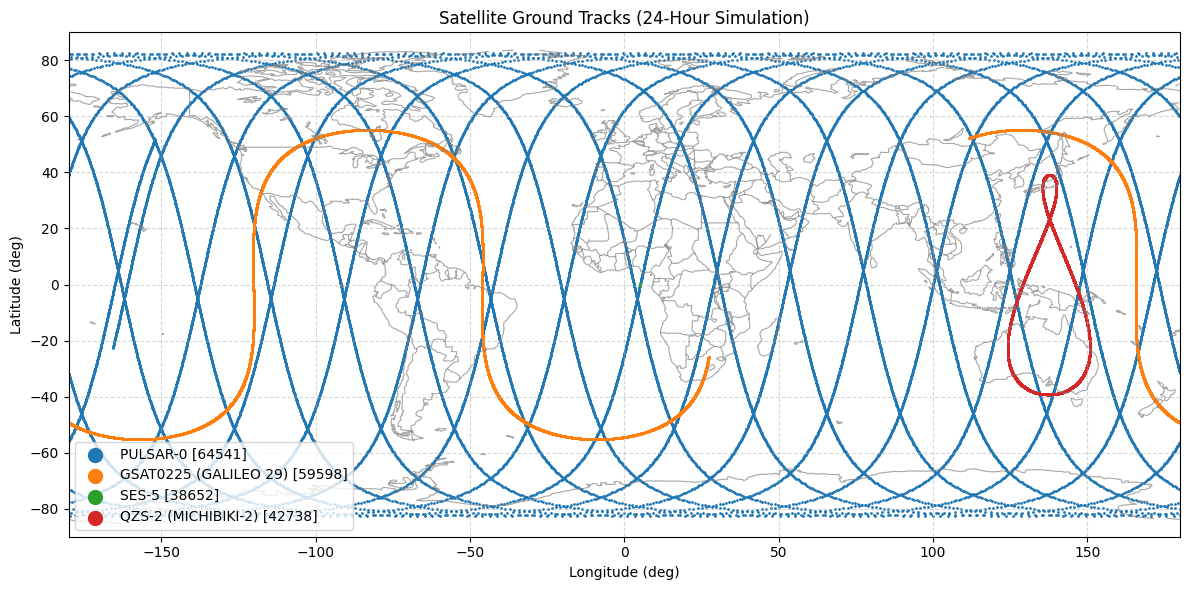

Saved velocity timeseries plot to /content/satellite_orbits/outputs/velocity_timeseries.png


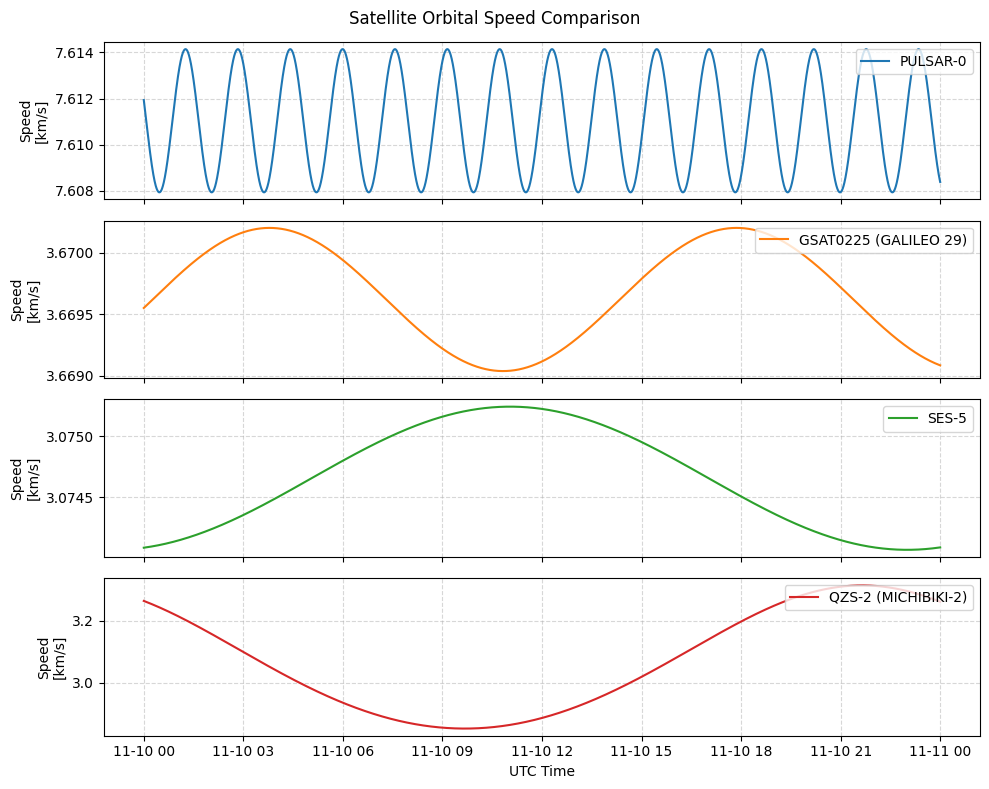

In [14]:
def load_coastline(path):
    """Load custom coastline data from world_map.txt.

    The file contains 'latitude longitude' per line, with blank lines separating distinct segments.
    """
    if not path.exists():
        raise FileNotFoundError(f"Coastline map file not found: {path}")

    segments = []
    current_segment = []

    with open(path, 'r') as f:
        for line in f:
            stripped = line.strip()
            if not stripped:
                if current_segment:
                    segments.append(current_segment)
                    current_segment = []
            else:
                parts = stripped.split()
                if len(parts) >= 2:
                    # Format is: latitude longitude
                    lat = float(parts[0])
                    lon = float(parts[1])
                    current_segment.append((lon, lat))

    if current_segment:
        segments.append(current_segment)

    return segments

# Define the constant global color list
COLORS = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

# Check dependencies
if 'elements' not in globals() or 'tracks' not in globals():
    raise NameError("Missing earlier stage dependencies: 'elements' or 'tracks' must be defined.")

# --- Load Map Data ---
coastlines = load_coastline(IN_DIR / 'world_map.txt')
print(f"Loaded {len(coastlines)} coastline segments.")

# --- Figure 1: 2D Ground Tracks ---
plt.figure(figsize=(12, 6))

# Plot the coastlines in gray
for seg in coastlines:
    lons, lats = zip(*seg)
    plt.plot(lons, lats, color='gray', linewidth=0.8, alpha=0.7)

# Plot each satellite's track using small dots to prevent cross-map wrap-around lines
for idx, (el, track) in enumerate(zip(elements, tracks)):
    lons = [pt['lon_deg'] for pt in track]
    lats = [pt['lat_deg'] for pt in track]
    color = COLORS[idx % len(COLORS)]

    plt.scatter(lons, lats, color=color, s=1, label=el['label'])

plt.title("Satellite Ground Tracks (24-Hour Simulation)")
plt.xlabel("Longitude (deg)")
plt.ylabel("Latitude (deg)")
plt.xlim(-180, 180)
plt.ylim(-90, 90)
plt.grid(True, linestyle='--', alpha=0.5)
# Make the legend markers larger for visibility
plt.legend(loc='lower left', markerscale=10)
plt.tight_layout()

track_plot_path = OUT_DIR / 'ground_tracks.png'
plt.savefig(track_plot_path, dpi=200)
print(f"Saved ground tracks plot to {track_plot_path}")
plt.show()

# --- Figure 2: Velocity Timeseries ---
fig, axs = plt.subplots(len(elements), 1, figsize=(10, 8), sharex=True)
if len(elements) == 1:
    axs = [axs]

for idx, (el, track) in enumerate(zip(elements, tracks)):
    ax = axs[idx]
    times_plot = [pt['time'] for pt in track]
    speeds = [pt['speed_km_s'] for pt in track]
    color = COLORS[idx % len(COLORS)]

    ax.plot(times_plot, speeds, color=color, linewidth=1.5, label=el['name'])
    ax.set_ylabel("Speed\n[km/s]")
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper right')
    # Disable automatic scientific/offset notation for the y-axis
    ax.get_yaxis().get_major_formatter().set_useOffset(False)

axs[-1].set_xlabel("UTC Time")
plt.suptitle("Satellite Orbital Speed Comparison")
plt.tight_layout()

vel_plot_path = OUT_DIR / 'velocity_timeseries.png'
plt.savefig(vel_plot_path, dpi=200)
print(f"Saved velocity timeseries plot to {vel_plot_path}")
plt.show()

### Stage 8: Export for Google Earth and Report

In this final stage, we package our simulated trajectories and orbit summaries into formats suitable for external distribution, visualization, and validation:
- **KML 2.2 Earth-Fixed Trajectories (`orbit_tracks_ecef.kml`)**: Visualizes the 3D orbits around the globe in absolute altitudes. This allows you to view the actual altitude of each satellite above the Earth.
- **KML 2.2 Time-Animated Ground Tracks (`orbit_animation.kml`)**: Uses the Google Earth `gx:MultiTrack` extension to animate the paths along the ground over the 24-hour simulation timeline. To prevent visual tracking errors, a new sub-track is created whenever a satellite crosses the $\pm 180^\circ$ anti-meridian.
- **Consolidated Text Report (`orbit_report.txt`)**: A complete text document containing the simulation settings, standard model caveats, the parsed Keplerian elements table from Stage 3, and the physical orbit summary table from Stage 6.
- **Final Package**: Zips all 5 generated artifacts (2 plots, 2 KMLs, and 1 report) into a single zip file for download.

---

### 🗺️ Google Earth Pro View Guide
1. **Launch Google Earth Pro** (Desktop version) or open [Google Earth Web](https://earth.google.com/web/).
2. Go to **File** -> **Open...** and select `orbit_tracks_ecef.kml` to see the 3D orbital paths wrapped around the globe.
3. Open `orbit_animation.kml`. A time slider will appear in the top-left corner of the viewport.
4. Click the **Play** button on the time slider to watch the satellites move concurrently along their paths over the course of the day!

### 🏁 "Run All" Verification Checklist
- [x] **Stage 1**: Directories generated and constants configured.
- [x] **Stage 2**: Native OMM GP JSON and data manifest extracted and loaded.
- [x] **Stage 3**: SGP4 mean elements correctly converted to standard Keplerian elements.
- [x] **Stage 4**: Shared 24-hour time window created from midnight of the newest epoch.
- [x] **Stage 5**: Orbit positions propagated and coordinate frames converted.
- [x] **Stage 6**: Orbit parameters and velocity extremes extracted and validated via assertions.
- [x] **Stage 7**: Ground tracks and velocity timeseries plotted and saved.
- [x] **Stage 8**: KML files and consolidated report exported, packaged, and downloaded.

In [15]:
def hex_to_kml_color(hex_color_str, alpha_hex="ff"):
    """Convert standard hex color (#rrggbb) to KML color order (aabbggrr)."""
    # Remove # if present
    hex_clean = hex_color_str.lstrip('#')
    r = hex_clean[0:2]
    g = hex_clean[2:4]
    b = hex_clean[4:6]
    # KML format is aabbggrr
    return f"{alpha_hex}{b}{g}{r}"

# --- 1. Build orbit_tracks_ecef.kml ---
# Register namespaces
ET.register_namespace('', "http://www.opengis.net/kml/2.2")
ET.register_namespace('gx', "http://www.google.com/kml/ext/2.2")

kml_ns = "http://www.opengis.net/kml/2.2"

# Create KML root
kml_root = ET.Element(f"{{{kml_ns}}}kml")
doc = ET.SubElement(kml_root, f"{{{kml_ns}}}Document")
doc_name = ET.SubElement(doc, f"{{{kml_ns}}}name")
doc_name.text = "Multi-Satellite Orbits | Earth-fixed"

# Add styles for each satellite
for idx, el in enumerate(elements):
    hex_col = to_hex(COLORS[idx % len(COLORS)])
    kml_col = hex_to_kml_color(hex_col)

    style = ET.SubElement(doc, f"{{{kml_ns}}}Style", id=f"style_{el['norad_id']}")

    # Icon style (placemark)
    icon_style = ET.SubElement(style, f"{{{kml_ns}}}IconStyle")
    icon_col = ET.SubElement(icon_style, f"{{{kml_ns}}}color")
    icon_col.text = kml_col
    icon = ET.SubElement(icon_style, f"{{{kml_ns}}}Icon")
    icon_href = ET.SubElement(icon, f"{{{kml_ns}}}href")
    icon_href.text = "http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png"

    # Line style (orbital path)
    line_style = ET.SubElement(style, f"{{{kml_ns}}}LineStyle")
    line_col = ET.SubElement(line_style, f"{{{kml_ns}}}color")
    line_col.text = kml_col
    line_width = ET.SubElement(line_style, f"{{{kml_ns}}}width")
    line_width.text = "2"

# Generate 3D ECEF geometry placemarks
for idx, (el, track) in enumerate(zip(elements, tracks)):
    placemark = ET.SubElement(doc, f"{{{kml_ns}}}Placemark")
    pl_name = ET.SubElement(placemark, f"{{{kml_ns}}}name")
    pl_name.text = el['name']

    style_url = ET.SubElement(placemark, f"{{{kml_ns}}}styleUrl")
    style_url.text = f"#style_{el['norad_id']}"

    line_str = ET.SubElement(placemark, f"{{{kml_ns}}}LineString")
    alt_mode = ET.SubElement(line_str, f"{{{kml_ns}}}altitudeMode")
    alt_mode.text = "absolute"

    coords_elem = ET.SubElement(line_str, f"{{{kml_ns}}}coordinates")
    coord_strings = []
    for pt in track:
        # ECEF coordinates are formatted as lon,lat,alt (altitude in meters)
        coord_strings.append(f"{pt['lon_deg']:.6f},{pt['lat_deg']:.6f},{pt['alt_km'] * 1000.0:.1f}")
    coords_elem.text = " ".join(coord_strings)

kml1_path = OUT_DIR / 'orbit_tracks_ecef.kml'
ET.ElementTree(kml_root).write(kml1_path, encoding='utf-8', xml_declaration=True)
print(f"Created KML: {kml1_path}")

# --- 2. Build orbit_animation.kml ---
gx_ns = "http://www.google.com/kml/ext/2.2"

anim_root = ET.Element(f"{{{kml_ns}}}kml")
anim_doc = ET.SubElement(anim_root, f"{{{kml_ns}}}Document")
anim_doc_name = ET.SubElement(anim_doc, f"{{{kml_ns}}}name")
anim_doc_name.text = "Multi-Satellite Ground Tracks | Animation"

# Reuse same styles
for idx, el in enumerate(elements):
    hex_col = to_hex(COLORS[idx % len(COLORS)])
    kml_col = hex_to_kml_color(hex_col)
    style = ET.SubElement(anim_doc, f"{{{kml_ns}}}Style", id=f"style_{el['norad_id']}")
    icon_style = ET.SubElement(style, f"{{{kml_ns}}}IconStyle")
    icon_col = ET.SubElement(icon_style, f"{{{kml_ns}}}color")
    icon_col.text = kml_col
    icon = ET.SubElement(icon_style, f"{{{kml_ns}}}Icon")
    icon_href = ET.SubElement(icon, f"{{{kml_ns}}}href")
    icon_href.text = "http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png"
    line_style = ET.SubElement(style, f"{{{kml_ns}}}LineStyle")
    line_col = ET.SubElement(line_style, f"{{{kml_ns}}}color")
    line_col.text = kml_col
    line_width = ET.SubElement(line_style, f"{{{kml_ns}}}width")
    line_width.text = "2"

for idx, (el, track) in enumerate(zip(elements, tracks)):
    placemark = ET.SubElement(anim_doc, f"{{{kml_ns}}}Placemark")
    pl_name = ET.SubElement(placemark, f"{{{kml_ns}}}name")
    pl_name.text = el['name']
    style_url = ET.SubElement(placemark, f"{{{kml_ns}}}styleUrl")
    style_url.text = f"#style_{el['norad_id']}"

    multi_track = ET.SubElement(placemark, f"{{{gx_ns}}}MultiTrack")
    interpolate = ET.SubElement(multi_track, f"{{{gx_ns}}}interpolate")
    interpolate.text = "1"

    # Downsample track: Keep one point per 60 seconds (every 12 steps if STEP_SECONDS=5)
    sample_interval = 60 // STEP_SECONDS
    sampled_track = track[::sample_interval]
    if track[-1] not in sampled_track:
        sampled_track.append(track[-1])

    # Segment tracks whenever there is a longitude wrap-around crossing of > 180 degrees
    sub_tracks = []
    current_sub = []

    for pt_idx, pt in enumerate(sampled_track):
        if current_sub:
            prev_lon = current_sub[-1]['lon_deg']
            curr_lon = pt['lon_deg']
            if abs(curr_lon - prev_lon) > 180.0:
                sub_tracks.append(current_sub)
                current_sub = []
        current_sub.append(pt)
    if current_sub:
        sub_tracks.append(current_sub)

    # Add each sub-track to the MultiTrack node
    for sub in sub_tracks:
        gx_track = ET.SubElement(multi_track, f"{{{gx_ns}}}Track")
        alt_mode = ET.SubElement(gx_track, f"{{{kml_ns}}}altitudeMode")
        alt_mode.text = "clampToGround"

        # Add temporal markers (<when>)
        for pt in sub:
            when = ET.SubElement(gx_track, f"{{{kml_ns}}}when")
            when.text = pt['time'].strftime('%Y-%m-%dT%H:%M:%SZ')

        # Add matching coordinates (<gx:coord>)
        for pt in sub:
            coord = ET.SubElement(gx_track, f"{{{gx_ns}}}coord")
            coord.text = f"{pt['lon_deg']:.6f} {pt['lat_deg']:.6f} 0"

kml2_path = OUT_DIR / 'orbit_animation.kml'
ET.ElementTree(anim_root).write(kml2_path, encoding='utf-8', xml_declaration=True)
print(f"Created KML: {kml2_path}")

# --- 3. Build orbit_report.txt ---
report_path = OUT_DIR / 'orbit_report.txt'

with open(report_path, 'w') as f:
    f.write("=========================================================================\n")
    f.write("Satellite Orbit Report - built during Space Career Week 2026, GNSS Academy\n")
    f.write("=========================================================================\n\n")
    f.write(f"{source_note}\n\n")
    f.write("--- Simulation Profile ---\n")
    f.write(f"Simulation Start (UTC): {sim_start}\n")
    f.write(f"Simulation End (UTC):   {sim_end}\n")
    f.write(f"Time Step Size:         {STEP_SECONDS} seconds\n")
    f.write(f"Total Grid Points:      {n_points}\n\n")
    f.write("--- Modeling Assumptions & Caveats ---\n")
    f.write("Disclaimer: This simulation utilizes classical Keplerian two-body analytical orbital mechanics\n")
    f.write("over a perfectly spherical, rotating Earth. It ignores non-spherical gravitational harmonics (J2),\n")
    f.write("atmospheric drag, solar radiation pressure, and third-body lunisolar perturbations.\n\n")
    f.write("--- Parsed Keplerian Elements Table (Stage 3) ---\n")
    for line in table_output:
        f.write(line + "\n")
    f.write("\n--- Orbit Summary Table (Stage 6) ---\n")
    for line in table_lines:
        f.write(line + "\n")

print(f"Created text report: {report_path}")

# --- 4. Zip the Five Outputs ---
zip_out_path = OUT_DIR / 'satellite_orbit_outputs.zip'
files_to_zip = [
    OUT_DIR / 'ground_tracks.png',
    OUT_DIR / 'velocity_timeseries.png',
    OUT_DIR / 'orbit_tracks_ecef.kml',
    OUT_DIR / 'orbit_animation.kml',
    OUT_DIR / 'orbit_report.txt'
]

with zipfile.ZipFile(zip_out_path, 'w') as zipf:
    for file_to_add in files_to_zip:
        if file_to_add.exists():
            zipf.write(file_to_add, arcname=file_to_add.name)
            print(f"Zipped: {file_to_add.name}")
        else:
            raise FileNotFoundError(f"Expected output file is missing: {file_to_add}")

print(f"\nSuccess! Created final consolidated zip: {zip_out_path}")

Created KML: /content/satellite_orbits/outputs/orbit_tracks_ecef.kml
Created KML: /content/satellite_orbits/outputs/orbit_animation.kml
Created text report: /content/satellite_orbits/outputs/orbit_report.txt
Zipped: ground_tracks.png
Zipped: velocity_timeseries.png
Zipped: orbit_tracks_ecef.kml
Zipped: orbit_animation.kml
Zipped: orbit_report.txt

Success! Created final consolidated zip: /content/satellite_orbits/outputs/satellite_orbit_outputs.zip


In [16]:
# --- Download Cell ---
from google.colab import files

# Trigger browser download for the final zip package
files.download(str(OUT_DIR / 'satellite_orbit_outputs.zip'))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>